In [1]:
import numpy as np
import pandas as pd

In [2]:
# Load raw dataset
df = pd.read_csv('HHS_Unaccompanied_Alien_Children_Program.csv')
df


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0
...,...,...,...,...,...,...
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Drop non-data rows and clean Date column
df = df.dropna(how='all').copy()
df

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0
...,...,...,...,...,...,...
715,"January 25, 2023",20.0,22.0,41.0,"7,538",180.0
716,"January 24, 2023",47.0,42.0,47.0,"7,433",175.0
717,"January 23, 2023",32.0,50.0,39.0,"7,280",181.0
718,"January 22, 2023",32.0,49.0,39.0,"7,122",227.0


In [4]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce'
                           )
df = df.dropna(subset=['Date']).sort_values('Date').reset_index(drop=True)

In [5]:


# Clean string formatting in numerical columns (e.g., thousands separators)
if df['Children in HHS Care'].dtype == object:
  df['Children in HHS Care'] = (
      df['Children in HHS Care'].str.replace(',', '').astype(float)
  )




In [6]:
# Standardize column naming convention
col_map = {
    'Children apprehended and placed in CBP custody*': 'CBP_Intake',
    'Children in CBP custody': 'CBP_Custody',
    'Children transferred out of CBP custody': 'CBP_Transfers',
    'Children in HHS Care': 'HHS_Care',
    'Children discharged from HHS Care': 'HHS_Discharges',
}
df = df.rename(columns=col_map)


In [7]:
# Logical Constraints Enforcement
# Constraint 1: CBP Transfers <= CBP Custody
# Constraint 2: HHS Discharges <= HHS Care
df['Transfer_Anomaly'] = df['CBP_Transfers'] > df['CBP_Custody']
df['Discharge_Anomaly'] = df['HHS_Discharges'] > df['HHS_Care']

# Cap illogical anomalies to the maximum active load threshold
df['CBP_Transfers'] = np.minimum(df['CBP_Transfers'], df['CBP_Custody'])
df['HHS_Discharges'] = np.minimum(df['HHS_Discharges'], df['HHS_Care'])

In [8]:
# 1. Total System Load (System-wide responsibility across CBP & HHS)
df['Total_System_Load'] = df['CBP_Custody'] + df['HHS_Care']

# 2. Net Daily Intake Pressure (Transfers into HHS - Discharges from HHS)
df['Net_Intake_Pressure'] = df['CBP_Transfers'] - df['HHS_Discharges']

# 3. Discharge Offset Ratio (Outflow relief efficiency relative to inflows)
df['Discharge_Offset_Ratio'] = np.where(
    df['CBP_Transfers'] > 0, df['HHS_Discharges'] / df['CBP_Transfers'], 1.0
)

# 4. Rolling Smoothing & Volatility Indicators
df['System_Load_7D_MA'] = df['Total_System_Load'].rolling(window=7,min_periods=1).mean()
df['System_Load_14D_MA'] = df['Total_System_Load'].rolling(window=14).mean()
df['Care_Load_Volatility_7D'] = df['Total_System_Load'].rolling(window=7).std()

# 5. Backlog Trajectory
df['Cumulative_Net_Backlog'] = df['Net_Intake_Pressure'].cumsum()

In [9]:
# Display computed features
df[['Date', 'Total_System_Load', 'Net_Intake_Pressure', 'Discharge_Offset_Ratio', 'System_Load_7D_MA']].head()

,Date,Total_System_Load,Net_Intake_Pressure,Discharge_Offset_Ratio,System_Load_7D_MA
0,2023-01-12,6619.0,-402.0,12.823529,6619.00
1,2023-01-22,7171.0,-188.0,5.820513,6895.00
2,2023-01-23,7330.0,-142.0,4.641026,7040.00
3,2023-01-24,7475.0,-133.0,4.166667,7148.75
4,2023-01-25,7560.0,-158.0,8.181818,7231.00


In [10]:
# System Stress Summary
print("=== UAC HEALTHCARE SYSTEM CAPACITY METRICS SUMMARY ===")
print(f"Peak System Load: {int(df['Total_System_Load'].max()):,} children")
print(f"Average Daily System Load: {int(df['Total_System_Load'].mean()):,} children")
print(f"Max Single-Day Inflow Pressure: +{int(df['Net_Intake_Pressure'].max())} children")
print(f"Total Days under Net Accumulation (Inflow > Outflow): {(df['Net_Intake_Pressure'] > 0).sum()} days")
print(f"Average Discharge Offset Ratio: {df['Discharge_Offset_Ratio'].mean():.2f}")


=== UAC HEALTHCARE SYSTEM CAPACITY METRICS SUMMARY ===
Peak System Load: 11,762 children
Average Daily System Load: 6,232 children
Max Single-Day Inflow Pressure: +196 children
Total Days under Net Accumulation (Inflow > Outflow): 232 days
Average Discharge Offset Ratio: 2.08


In [ ]:
# !pip install "numpy<2"

In [18]:
# !pip install --upgrade numpy pandas scipy matplotlib seaborn scikit-learn

   ---------------------------------------- 15.9/15.9 MB 4.5 MB/s  0:00:03
   ---------------------------------------- 11.4/11.4 MB 5.3 MB/s  0:00:02
   ---------------------------------------- 7.8/7.8 MB 5.2 MB/s  0:00:01
   ---------------------------------------- 11.2/11.2 MB 5.4 MB/s  0:00:02
   ---------------------------------------- 1.5/1.5 MB 4.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.5.2
    Uninstalling scikit-learn-1.5.2:
      Successfully uninstalled scikit-learn-1.5.2
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.4.3
    Uninstalling matplotlib-3.4.3:
      Successfully uninstalled

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
evidently 0.1.58.dev0 requires dataclasses>=0.6, which is not installed.
evidently 0.1.58.dev0 requires statsmodels>=0.12.2, which is not installed.
database-connect 0.1.66 requires cassandra-driver, which is not installed.
database-connect 0.1.66 requires ensure, which is not installed.
bokeh 3.4.1 requires xyzservices>=2021.09.1, which is not installed.
evidently 0.1.58.dev0 requires PyYAML~=5.1, but you have pyyaml 6.0.1 which is incompatible.
credit-card-fraud-detection 0.0.1 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
credit-card-fraud-detection 0.0.1 requires scikit-learn==1.5.2, but you have sciki

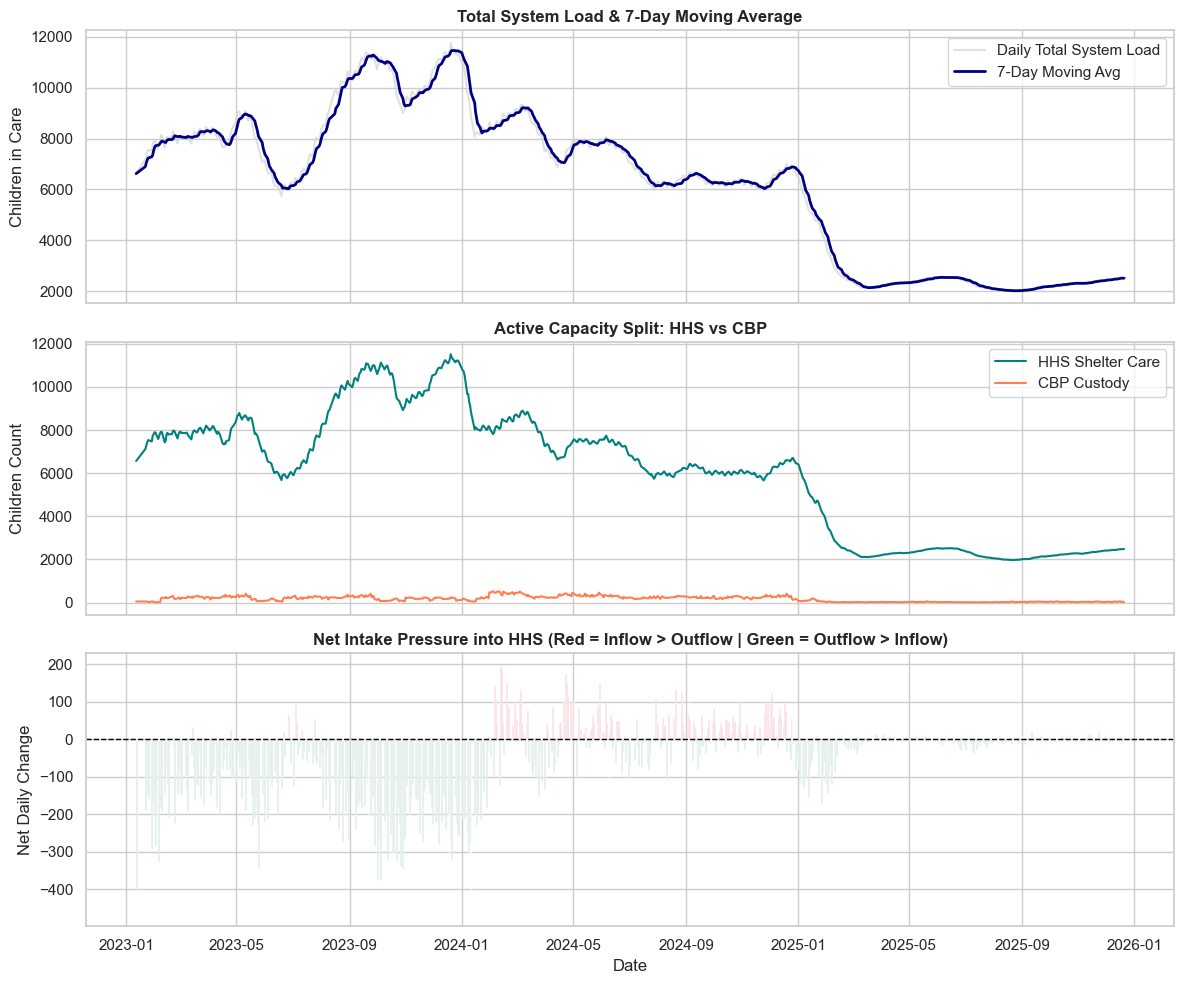

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Convert Series to numpy arrays to fix the Matplotlib/Pandas indexing error
dates = df['Date'].to_numpy()
total_load = df['Total_System_Load'].to_numpy()
load_ma = df['System_Load_7D_MA'].to_numpy()
hhs_care = df['HHS_Care'].to_numpy()
cbp_custody = df['CBP_Custody'].to_numpy()
net_pressure = df['Net_Intake_Pressure'].to_numpy()

# 1. Total System Load & 7D Moving Average Trend
axes[0].plot(
    dates, total_load, label='Daily Total System Load', color='lightgrey', alpha=0.7
)
axes[0].plot(
    dates, load_ma, label='7-Day Moving Avg', color='navy', linewidth=2
)
axes[0].set_title(
    'Total System Load & 7-Day Moving Average', fontsize=12, fontweight='bold'
)
axes[0].set_ylabel('Children in Care')
axes[0].legend(loc='upper right')

# 2. CBP Custody vs HHS Care Split
axes[1].plot(dates, hhs_care, label='HHS Shelter Care', color='teal', linewidth=1.5)
axes[1].plot(dates, cbp_custody, label='CBP Custody', color='coral', linewidth=1.5)
axes[1].set_title('Active Capacity Split: HHS vs CBP', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Children Count')
axes[1].legend(loc='upper right')

# 3. Net Daily Intake Pressure
colors = np.where(net_pressure > 0, 'crimson', 'seagreen')
axes[2].bar(dates, net_pressure, color=colors, alpha=0.7, width=1.0)
axes[2].axhline(0, color='black', linestyle='--', linewidth=1)
axes[2].set_title(
    'Net Intake Pressure into HHS (Red = Inflow > Outflow | Green = Outflow > Inflow)',
    fontsize=12,
    fontweight='bold',
)
axes[2].set_ylabel('Net Daily Change')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

In [21]:
# Export processed data for Streamlit dashboard ingestion
df.to_csv('processed_uac_analytics.csv', index=False)
print("Saved processed dataset as 'processed_uac_analytics.csv'.")

Saved processed dataset as 'processed_uac_analytics.csv'.
